# Буткемп, электронный relative-value трейдинг, день 19 — queue-aware market making и toxicity gate

На пятничной лекции задали выбрать одну стратегию из презентации и прогнать её через event-driven движок. Я взял **пассивный маркет-мейкинг с гейтом по токсичности очереди** — order-flow-imbalance market making. Гипотеза такая: queue imbalance на Bybit подсказывает, какая сторона котировки соберёт adverse selection; если эту сторону не котировать, распределение markout сдвинется вправо.

Протокол:
1. **Day 1** (2026-07-01, 12:00–14:00 UTC) — только калибровка порога по signal evidence. Параметры замораживаются.
2. **Day 2** (2026-07-02, 12:00–14:00 UTC) — out-of-sample, порог не пересматривается.
3. Ablations: baseline, random gate, **time-shifted qimb** (60 с назад), qimb, own microprice, lead (Binance) microprice, combined.
4. Экономика: maker fee в трёх точках — **+0.1, 0 и −0.5 bp**; 1 тик = 0.1 USD. Главный результат — **разложение PnL и проверка, есть ли сигнальный edge**, а не точечный плюс. Если lower bound CI ≤ 0, так и пишу; rebate −0.5 bp — верхняя граница MM-тира, не база.
5. PnL раскладывается на **spread capture, inventory PnL и fees**; если spread capture неотличим от нуля, так и пишу.

## Данные и сигналы

Исполнение — на Bybit BTCUSDT (top-of-book 100 мс + трейды). Binance BTCUSDT служит только лидером для сигнала, без исполнения. Все сигналы point-in-time: значение на строке $i$ использует только данные до $i$. Для каждого touch-трейда считаю markout через 1 с и 10 с от цены филла — это evidence до бэктеста.

Сигналы: $qimb=(\text{bid\_size}-\text{ask\_size})/(\text{bid\_size}+\text{ask\_size})$, $mp=(\text{microprice}-\text{mid})/\text{tick}$, $lead=(\text{microprice}_{BN}-\text{mid}_{BN})/\text{tick}$.

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, heapq, math, warnings
warnings.filterwarnings('ignore'); pd.set_option('display.width',180); pd.set_option('display.max_columns',40)
D='/Users/b.kotov/Downloads/'; Q=D+'l2_executable_quotes_100ms_10000.parquet'; tick=0.1
def _panel(ex,asset,d0,d1):
    return duckdb.connect().execute(f"""SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
      FROM read_parquet('{Q}') WHERE asset='{asset}' AND exchange='{ex}'
      AND event_time>=TIMESTAMPTZ '{d0}' AND event_time<TIMESTAMPTZ '{d1}' ORDER BY event_time""").df().reset_index(drop=True)
def _trades(ex,d0,d1):
    f=D+('bybit_anon_trades_20260701_20260703.parquet' if ex=='Bybit' else 'binance_anon_trades_20260701_20260703.parquet')
    return duckdb.connect().execute(f"""SELECT event_time, price, amount FROM read_parquet('{f}') WHERE symbol='BTCUSDT'
      AND event_time>=TIMESTAMPTZ '{d0}' AND event_time<TIMESTAMPTZ '{d1}' ORDER BY event_time""").df()
def load_day(day):
    d0=f'2026-07-0{day} 12:00:00+00'; d1=f'2026-07-0{day} 14:00:00+00'
    by=_panel('Bybit','BTC',d0,d1); bn=_panel('Binance','BTC',d0,d1); tr=_trades('Bybit',d0,d1)
    n=len(by); T=np.array(by.event_time.astype('int64'))
    mid=by.mid.values; bb=by.best_bid.values; ba=by.best_ask.values; bsz=by.best_bid_amount.values; asz=by.best_ask_amount.values
    bn2=pd.merge_asof(by[['event_time']],bn[['event_time','mid','best_bid','best_ask','best_bid_amount','best_ask_amount']],
                      on='event_time',direction='backward',tolerance=pd.Timedelta('1s'))
    bm=bn2.mid.values; bbid=bn2.best_bid.values; bask=bn2.best_ask.values; bbsz=bn2.best_bid_amount.values; basz=bn2.best_ask_amount.values
    tt=np.array(tr.event_time.astype('int64')); idx=np.searchsorted(T,tt,'right')-1
    ok=(idx>=0)&(idx<n); keep=np.where(ok)[0]; idx=idx[keep]; tt=tt[keep]; tr=tr.iloc[keep].reset_index(drop=True)
    px=tr.price.values; amt=tr.amount.values
    qimb=(bsz-asz)/np.maximum(bsz+asz,1e-9)
    bmp=(bb*asz+ba*bsz)/np.maximum(bsz+asz,1e-9); bnmp=(bbid*basz+bask*bbsz)/np.maximum(bbsz+basz,1e-9)
    mp=(bmp-mid)/tick; lead=(bnmp-bm)/tick; lead=np.where(np.isfinite(lead),lead,0.0)
    is_bid=np.abs(px-bb[idx])<=tick/2; is_ask=np.abs(px-ba[idx])<=tick/2
    ev=[]
    for j in np.where(is_bid|is_ask)[0]:
        k=idx[j]
        if k+100>=n: continue
        side=1 if is_bid[j] else -1
        mk1=(mid[k+10]-px[j])/tick if side==1 else (px[j]-mid[k+10])/tick
        mk10=(mid[k+100]-px[j])/tick if side==1 else (px[j]-mid[k+100])/tick
        ev.append((side,mk1,mk10,qimb[k],mp[k],lead[k]))
    ev=pd.DataFrame(ev,columns=['side','mk1','mk10','qimb','mp','lead'])
    return dict(day=day,T=T,mid=mid,bb=bb,ba=ba,bsz=bsz,asz=asz,idx=idx,px=px,amt=amt,tt_tr=tt,
                qimb=qimb,mp=mp,lead=lead,evidence=ev,d0=d0,d1=d1)
D1=load_day(1); D2=load_day(2)
print('day1: %d строк, %d трейдов; day2: %d строк, %d трейдов'%(len(D1['mid']),len(D1['px']),len(D2['mid']),len(D2['px'])))
print('qimb quantiles day1:',np.round(np.quantile(D1['qimb'],[.1,.25,.5,.75,.9]),3))

day1: 70679 строк, 454717 трейдов; day2: 71537 строк, 476707 трейдов
qimb quantiles day1: [-0.869 -0.559  0.075  0.65   0.896]


## Signal evidence: markout по бакетам

Перед бэктестом проверяю, разделяет ли сигнал markout. Для каждого touch-филла считаю markout через 1 с и 10 с, сортирую по adverse-знаку сигнала и смотрю на крайние бакеты. Размах меньше пары тиков — сигнала нет, и это честный отрицательный результат.

,day,signal,mk1 with,mk1 against,spread mk1,spread mk10,n per bucket
0,1,qimb,-21.28,-45.52,-24.23,-28.24,35937
1,1,mp,-21.35,-45.55,-24.19,-27.58,35937
2,1,lead,-27.09,-44.33,-17.24,6.41,35937
3,2,qimb,-19.13,-48.81,-29.69,-20.09,38187
4,2,mp,-18.95,-48.86,-29.90,-20.66,38187
5,2,lead,-27.16,-41.61,-14.45,4.20,38187


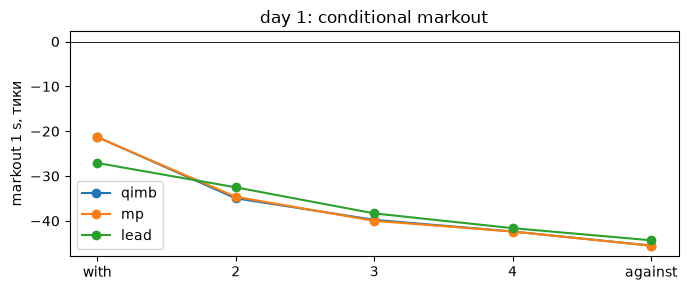

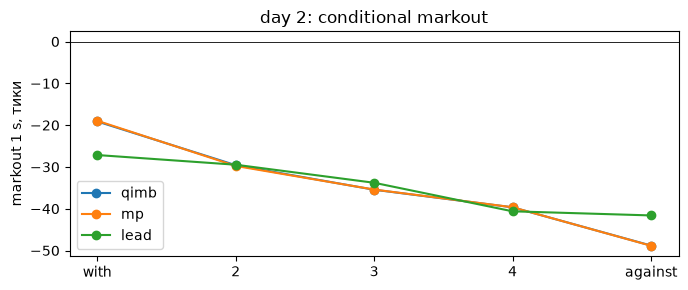

In [2]:
def evidence_table(d,col):
    e=d['evidence'].copy(); e['adv']=-e[col]*e.side
    e['b']=pd.qcut(e.adv.rank(method='first'),5,labels=['1 with','2','3','4','5 against'])
    return e.groupby('b',observed=True).agg(mk1=('mk1','mean'),mk10=('mk10','mean'),n=('mk1','size'))
rows=[]
for day,d in [(1,D1),(2,D2)]:
    for name in ['qimb','mp','lead']:
        g=evidence_table(d,name)
        rows.append({'day':day,'signal':name,'mk1 with':round(g.mk1.iloc[0],2),'mk1 against':round(g.mk1.iloc[-1],2),
                     'spread mk1':round(g.mk1.iloc[-1]-g.mk1.iloc[0],2),'spread mk10':round(g.mk10.iloc[-1]-g.mk10.iloc[0],2),
                     'n per bucket':int(g.n.iloc[0])})
EV=pd.DataFrame(rows); display(EV)
for day,d in [(1,D1),(2,D2)]:
    fig,ax=plt.subplots(figsize=(7,3))
    for name in ['qimb','mp','lead']:
        g=evidence_table(d,name); ax.plot(range(5),g.mk1.values,'o-',label=name)
    ax.axhline(0,color='k',lw=.6); ax.set_xticks(range(5)); ax.set_xticklabels(['with','2','3','4','against'])
    ax.set_ylabel('markout 1 s, тики'); ax.set_title('day %d: conditional markout'%day); ax.legend(); plt.tight_layout(); plt.show()

## Движок и стратегия

Движок — из hw18: priority queue, часы replay/strategy/exchange, latency-очереди, пассивные филлы через очередь впереди, cancel latency, fill report. `GatedMM` каждые 5 с снимает старые котировки и ставит новые на touch; сторону блокирует, если сигнал предсказывает adverse selection. Инвентарь ограничен ±2 **в момент постановки**; между котировками лимит может пробиваться (в таблицах max inv 6–9 BTC) — это ограничение, а не жёсткий risk-контроль. Taker-хеджа нет.

Гейт: bid блокируется при `qimb < −qth`, ask — при `qimb > +qth`; для `mp`/`lead` знак аналогичен. Порог — 0.8-квантиль |сигнала| на day1, заморожен. Time-shifted placebo берёт qimb с лагом 60 с при том же пороге.

In [3]:
class Cfg(dict):
    def __getattr__(self,k): return self[k]
    def __setattr__(self,k,v): self[k]=v
def draw(rng,base,mult):
    if mult<=0: return 0
    return int(rng.lognormal(math.log(max(base*mult,1)),0.35))

class GatedMM:
    def __init__(self,eng,mode='none',qth=.5,mth=.5,lth=.5,inv_max=2,p_bid=.1,p_ask=.1,lag=0,seed=11):
        self.e=eng; self.mode=mode; self.qth=qth; self.mth=mth; self.lth=lth; self.inv_max=inv_max
        self.p_bid=p_bid; self.p_ask=p_ask; self.lag=lag; self.rng=np.random.default_rng(seed)
        self.live=[]; self.posted=0; self.blocked=0
    def on_data(self,now,i,book):
        if i%50: return
        for oid in self.live: self.e.send_cancel(oid,now)
        self.live=[]
        q=QIMB[max(i-self.lag,0)] if self.lag else book['qimb']
        ab=aa=True
        if self.mode in ('qimb','both'): ab &= q>=-self.qth; aa &= q<=self.qth
        if self.mode in ('mp','both'): ab &= book['mp']>=-self.mth; aa &= book['mp']<=self.mth
        if self.mode=='lead': ab &= book['lead']>=-self.lth; aa &= book['lead']<=self.lth
        if self.mode=='shift':
            qs=QIMB[max(i-600,0)]; ab &= qs>=-self.qth; aa &= qs<=self.qth
        if self.mode=='random': ab=self.rng.random()>=self.p_bid; aa=self.rng.random()>=self.p_ask
        if self.e.inv>=self.inv_max: ab=False
        if self.e.inv<=-self.inv_max: aa=False
        self.posted+=int(ab)+int(aa); self.blocked+=int(not ab)+int(not aa)
        if ab:
            oid=self.e.send_order('B',book['bid'],1.0,now,passive=True)
            if oid: self.live.append(oid)
        if aa:
            oid=self.e.send_order('S',book['ask'],1.0,now,passive=True)
            if oid: self.live.append(oid)

class Engine:
    def __init__(self,cfg,strat,seed=7):
        self.cfg=cfg; self.strat=strat; self.rng=np.random.default_rng(seed); self.seq=0
        self.q=[]; self.now=0; self.book=None; self.pending={}; self.next_oid=1
        self.log=[]; self.fills=[]; self.rejects=0; self.cash=0.; self.inv=0.; self.fee=0.; self.equity=[]; self.max_inv=0.; self.filled_qty=0.; self.filled_oids=set()
    def sched(self,ts,kind,p):
        ts=int(ts)
        if ts<self.now: ts=self.now+1
        self.seq+=1; heapq.heappush(self.q,(ts,self.seq,kind,p))
    def lat(self,base): return draw(self.rng,base,self.cfg.mult) if self.cfg.use_latency else 0
    def send_order(self,side,price,qty,now,passive=True):
        if abs(price/tick-round(price/tick))>1e-9: self.rejects+=1; return None
        if self.cfg.reject_prob and self.rng.random()<self.cfg.reject_prob: self.rejects+=1; return None
        oid=self.next_oid; self.next_oid+=1
        self.sched(now+self.lat(10_000_000)+self.lat(20_000_000),'ORDER',{'oid':oid,'side':side,'price':round(price,2),'qty':qty,'passive':passive})
        return oid
    def send_cancel(self,oid,now):
        o=self.pending.get(oid)
        if not o or o.get('cancelling'): return
        o['cancelling']=True
        self.sched(now+(self.lat(20_000_000) if self.cfg.use_cancel_latency else 0),'CANCEL',{'oid':oid})
    def emit_fill(self,oid,qty,price,now):
        o=self.pending[oid]; o['qty']-=qty
        self.fills.append({'t':now,'i':self.book['i'],'oid':oid,'side':o['side'],'price':price,'qty':qty})
        if o['qty']<=1e-9: del self.pending[oid]
        self.sched(now+self.lat(5_000_000),'FILL',{'oid':oid,'side':o['side'],'price':price,'qty':qty})
    def match(self,price,amount,now):
        for oid,o in list(self.pending.items()):
            cur_bid=BB[self.book['i']]; cur_ask=BA[self.book['i']]
            want='B' if abs(price-cur_bid)<=1e-9 else ('S' if abs(price-cur_ask)<=1e-9 else None)
            if want is None or o['side']!=want or abs(price-o['price'])>1e-9: continue
            c=min(amount,o['queue']); o['queue']=max(0.,o['queue']-c); amount-=c
            if amount>0 and o['queue']<=1e-9:
                f=min(amount,o['qty']); self.emit_fill(oid,f,o['price'],now); amount-=f
    def run(self):
        for i in range(N):
            self.sched(TT[i],'MD_EX',{'i':i}); self.sched(TT[i]+self.lat(30_000_000),'MD_STRAT',{'i':i})
        for j in range(len(PX)): self.sched(TT_TR[j],'TRADE',{'price':PX[j],'amount':AMT[j]})
        self.now=TT[0]-1
        while self.q:
            ts,seq,kind,p=heapq.heappop(self.q)
            if ts<self.now: raise RuntimeError('time paradox')
            self.now=ts; self.log.append((ts,kind,str(p)[:120]))
            if kind=='MD_EX':
                i=p['i']; self.book={'i':i,'mid':MID[i],'bid':BB[i],'ask':BA[i],'bsz':BSZ[i],'asz':ASZ[i],'qimb':QIMB[i],'mp':MP[i],'lead':LEAD[i]}
                if self.cfg.use_queue:
                    for oid,o in list(self.pending.items()):
                        cv=(CB[i] if o['side']=='B' else CA[i])*self.cfg.ahead_frac
                        if cv>0: o['queue']=max(0.,o['queue']-cv)
                self.equity.append((ts,(self.cash+self.inv*MID[i])/tick-self.fee))
            elif kind=='TRADE':
                if self.cfg.use_queue: self.match(p['price'],p['amount'],ts)
            elif kind=='MD_STRAT':
                i=p['i']; self.strat.on_data(ts,i,{'i':i,'mid':MID[i],'bid':BB[i],'ask':BA[i],'qimb':QIMB[i],'mp':MP[i],'lead':LEAD[i]})
            elif kind=='ORDER':
                price=p['price']; side=p['side']
                if p['passive']:
                    if side=='B' and price>self.book['bid']+1e-9: self.rejects+=1; continue
                    if side=='S' and price<self.book['ask']-1e-9: self.rejects+=1; continue
                    self.pending[p['oid']]={'side':side,'price':price,'qty':p['qty'],'queue':self.book['bsz'] if side=='B' else self.book['asz']}
            elif kind=='CANCEL': self.pending.pop(p['oid'],None)
            elif kind=='FILL':
                sgn=1 if p['side']=='B' else -1
                self.cash-=sgn*p['price']*p['qty']; self.inv+=sgn*p['qty']; self.max_inv=max(self.max_inv,abs(self.inv)); self.filled_qty+=p['qty']; self.filled_oids.add(p['oid'])
                self.fee+=self.cfg.maker_bp*1e-4*MID[self.book['i']]/tick*p['qty']
        mtm=(self.cash+self.inv*MID[-1])/tick
        return {'mtm':mtm,'fee':self.fee,'net':mtm-self.fee,'fills':len(self.fills),'rejects':self.rejects,'pending':len(self.pending),'max_inv':self.max_inv,'filled_qty':self.filled_qty,'orders_filled':len(self.filled_oids)}

BASE=dict(use_latency=True,mult=1.0,use_queue=True,ahead_frac=0.5,use_cancel_latency=True,reject_prob=0.0,maker_bp=0.0,taker_bp=2.0)
def use(d):
    global N,TT,MID,BB,BA,BSZ,ASZ,PX,AMT,TT_TR,QIMB,MP,LEAD,CB,CA
    N=len(d['mid']); TT=d['T']; MID=d['mid']; BB=d['bb']; BA=d['ba']; BSZ=d['bsz']; ASZ=d['asz']
    PX=d['px']; AMT=d['amt']; TT_TR=d['tt_tr']; QIMB=d['qimb']; MP=d['mp']; LEAD=d['lead']
    tbv=np.zeros(N); tav=np.zeros(N)
    for j in range(len(PX)):
        k=d['idx'][j]
        if abs(PX[j]-BA[k])<=tick/2: tav[k]+=AMT[j]
        elif abs(PX[j]-BB[k])<=tick/2: tbv[k]+=AMT[j]
    db=np.maximum(-np.diff(BSZ,prepend=BSZ[0]),0); da=np.maximum(-np.diff(ASZ,prepend=ASZ[0]),0)
    CB=np.maximum(db-tbv,0); CA=np.maximum(da-tav,0)

def run_variant(d,mode='none',cfg_over=None,**kw):
    use(d); cfg=Cfg(dict(BASE)); cfg.update(cfg_over or {}); e=Engine(cfg,None); s=GatedMM(e,mode=mode,**kw); e.strat=s; r=e.run(); return e,r,s

## Калибровка и ablation

Порог `qth` — 0.8-квантиль |qimb| на day1, заморожен. У random gate вероятность блока каждой стороны равна доле блокировок qimb-гейта на day1. Time-shifted placebo берёт qimb с лагом 60 с при том же пороге. Сравниваю по PnL/fill и spread capture, а не только по сумме.

In [4]:
use(D1)
qth=float(np.quantile(np.abs(QIMB[::50]),.8)); mth=float(np.quantile(np.abs(MP[::50]),.8)); lth=float(np.quantile(np.abs(LEAD[::50]),.8))
p_bid=float(np.mean(QIMB[::50]<-qth)); p_ask=float(np.mean(QIMB[::50]>qth))
print('qth %.4f, mth %.2f, lth %.2f; p_bid %.3f p_ask %.3f'%(qth,mth,lth,p_bid,p_ask))
variants=[('baseline','none',{}),('random','random',{'p_bid':p_bid,'p_ask':p_ask}),('shifted qimb','shift',{}),
          ('qimb','qimb',{}),('microprice','mp',{}),('lead mp','lead',{}),('qimb+mp','both',{})]
rows=[]; stores={}
for day,d in [(2,D2)]:
    for name,mode,kw in variants:
        e,r,s=run_variant(d,mode=mode,qth=qth,mth=mth,lth=lth,**kw); stores[(day,name)]=(e,r,s)
        fees={bp:sum(bp*1e-4*f['price']/tick*f['qty'] for f in e.fills) for bp in [0.1,0.0,-0.5]}
        spread=sum((MID[f['i']]-f['price'])/tick*f['qty']*(1 if f['side']=='B' else -1) for f in e.fills)
        qty=max(r['filled_qty'],1e-9)
        rows.append({'variant':name,'orders filled':r['orders_filled'],'filled BTC':round(qty,2),'posted':s.posted,
                     'fill rate':round(r['orders_filled']/max(s.posted,1),3),'max inv':round(r['max_inv'],1),
                     'spread/BTC':round(spread/qty,2),'net 0bp':round(r['mtm']-fees[0.0],1),
                     'net -0.5bp':round(r['mtm']-fees[-0.5],1),'net +0.1bp':round(r['mtm']-fees[0.1],1),'inventory PnL':round(r['mtm']-spread,1),
                     'PnL/BTC 0bp':round((r['mtm']-fees[0.0])/qty,2)})
AB=pd.DataFrame(rows); display(AB.round(2))

qth 0.9157, mth 0.46, lth 0.37; p_bid 0.091 p_ask 0.110


,variant,orders filled,filled BTC,posted,fill rate,max inv,spread/BTC,net 0bp,net -0.5bp,net +0.1bp,inventory PnL,PnL/BTC 0bp
0,baseline,408,134.44,2159,0.19,8.5,0.54,29203.2,33340.4,28375.8,29131.2,217.23
1,random,361,119.22,1897,0.19,8.8,0.52,31496.7,35165.3,30763.0,31435.1,264.19
2,shifted qimb,377,114.18,2016,0.19,7.7,0.55,21361.5,24875.0,20658.8,21299.0,187.09
3,qimb,377,117.92,2006,0.19,7.0,0.72,26853.3,30481.9,26127.6,26768.9,227.72
4,microprice,388,123.02,2070,0.19,6.1,0.60,25851.9,29637.6,25094.8,25777.7,210.15
5,lead mp,357,109.95,1966,0.18,8.0,0.54,24962.8,28345.8,24286.2,24903.2,227.03
6,qimb+mp,389,123.64,2062,0.19,6.1,0.60,25808.7,29613.8,25047.7,25734.2,208.73


## PnL, attribution и bootstrap

Для каждого варианта: `net = spread capture + inventory PnL − fees`. Spread capture — сумма `(mid_at_fill − fill_price)·side`; inventory PnL — остаток, то есть mark-to-market позиции после филла. Bootstrap по одноминутным блокам даёт CI на mtm; fee сдвигает его детерминированно. Если spread capture неотличим от нуля, гейт — управление инвентарём, а не alpha.

,day,variant,mtm,CI 2.5%,CI 97.5%,net 0bp,net -0.5bp,net +0.1bp,filled BTC,PnL/BTC 0bp
0,2,baseline,29203.2,-14457.8,73526.6,29203.2,33340.4,28375.8,134.44,217.23
1,2,random,31496.7,-23224.9,86465.8,31496.7,35165.3,30763.0,119.22,264.19
2,2,shifted qimb,21361.5,-7068.3,47589.6,21361.5,24875.0,20658.8,114.18,187.09
3,2,qimb,26853.3,-6845.1,60060.7,26853.3,30481.9,26127.6,117.92,227.72
4,2,microprice,25851.9,-10297.6,59955.4,25851.9,29637.6,25094.8,123.02,210.15
5,2,lead mp,24962.8,-21820.3,70510.0,24962.8,28345.8,24286.2,109.95,227.03
6,2,qimb+mp,25808.7,-10237.7,59797.7,25808.7,29613.8,25047.7,123.64,208.73


baseline 4 equal-block net (ticks): [ 1049.  2922.    36. 25196.]
qimb 4 equal-block net (ticks): [  554.  5967.  2286. 18020.]


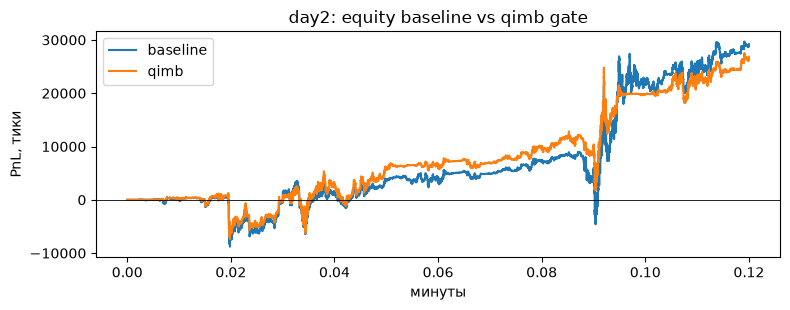

paired bootstrap qimb−baseline: mean -21.0 CI [-20951.9; 12974.7]
paired bootstrap qimb−random: mean -39.9 CI [-36674.4; 24933.0]
spread/BTC baseline: CI [0.52; 0.55]
spread/BTC qimb: CI [0.59; 0.65]


In [5]:
def fee_sum(e,bp): return sum(bp*1e-4*f['price']/tick*f['qty'] for f in e.fills)
def minute_diffs(e):
    eq=np.array([(t,v) for t,v in e.equity]); k=max(1,len(eq)//120)
    vals=eq[::k,1]; return np.diff(vals)
def boot_ci(x,n=2000,seed=1):
    rng=np.random.default_rng(seed); m=[]
    for _ in range(n): m.append(rng.choice(x,size=len(x),replace=True).sum())
    return np.quantile(m,[.025,.5,.975])
rows=[]
for day in (2,):
    for name in ['baseline','random','shifted qimb','qimb','microprice','lead mp','qimb+mp']:
        e,r,s=stores[(day,name)]
        fee0=fee_sum(e,0.0); feer=fee_sum(e,-0.5); ci=boot_ci(minute_diffs(e))
        rows.append({'day':day,'variant':name,'mtm':round(r['mtm'],1),'CI 2.5%':round(ci[0],1),'CI 97.5%':round(ci[2],1),
                     'net 0bp':round(r['mtm']-fee0,1),'net -0.5bp':round(r['mtm']-feer,1),'net +0.1bp':round(r['mtm']-fee_sum(e,0.1),1),
                     'filled BTC':round(r['filled_qty'],2),'PnL/BTC 0bp':round((r['mtm']-fee0)/max(r['filled_qty'],1e-9),2)})
CI=pd.DataFrame(rows); display(CI)
# hourly PnL day2 baseline vs qimb
for name in ['baseline','qimb']:
    e,r,s=stores[(2,name)]; eq=np.array([(t,v) for t,v in e.equity]); k=max(1,len(eq)//4)
    vals=eq[::k,1]
    print(name,'4 equal-block net (ticks):',np.round(np.diff(vals),0))
fig,ax=plt.subplots(figsize=(8,3.2))
for name in ['baseline','qimb']:
    e,r,s=stores[(2,name)]; eq=np.array([(t,v) for t,v in e.equity])
    ax.plot((eq[:,0]-eq[0,0])/1e9/60,eq[:,1],label=name)
ax.axhline(0,color='k',lw=.6); ax.set_xlabel('минуты'); ax.set_ylabel('PnL, тики')
ax.set_title('day2: equity baseline vs qimb gate'); ax.legend(); plt.tight_layout(); plt.show()
# парный bootstrap разности qimb − baseline / qimb − random по 1-мин блокам
def mdiffs(name):
    e,_,_=stores[(2,name)]; return minute_diffs(e)
b=mdiffs('baseline'); q=mdiffs('qimb'); rnd=mdiffs('random')
for label,x in [('qimb−baseline',q-b),('qimb−random',q-rnd)]:
    ci=boot_ci(x); print('paired bootstrap %s: mean %.1f CI [%.1f; %.1f]'%(label,np.mean(x),ci[0],ci[2]))
# CI на spread capture per BTC (бутстреп по филлам)
def spread_ci(name,n=1000):
    e,_,_=stores[(2,name)]; vals=np.array([((MID[f['i']]-f['price'])/tick)*(1 if f['side']=='B' else -1) for f in e.fills])
    rng=np.random.default_rng(2); m=[rng.choice(vals,size=len(vals),replace=True).mean() for _ in range(n)]
    return np.quantile(m,[.025,.975])
for name in ['baseline','qimb']:
    lo,hi=spread_ci(name); print('spread/BTC %s: CI [%.2f; %.2f]'%(name,lo,hi))


## Latency и robustness

Настоящий сигнал должен умирать с задержкой, поэтому гоняю qimb-гейт на day2 с лагом сигнала 0/200/500/1000/2000 мс и с множителем quote latency 0.5/1/2. Отдельно смотрю sensitivity порога 0.6–0.9: порог выбирается только на day1, но устойчивость результата проверяется на day2.

In [6]:
lat_rows=[]
for lag in [0,2,5,10,20]:
    e,r,s=run_variant(D2,mode='qimb',qth=qth,lag=lag); lat_rows.append({'signal lag, steps':lag,'lag, ms':lag*100,
        'filled BTC':round(r['filled_qty'],2),'PnL/BTC 0bp':round((r['mtm']-fee_sum(e,0.0))/max(r['filled_qty'],1e-9),2),
        'net -0.5bp':round(r['mtm']-fee_sum(e,-0.5),1)})
for mult in [0.5,1.0,2.0]:
    e,r,s=run_variant(D2,mode='qimb',qth=qth,cfg_over={'mult':mult}); lat_rows.append({'signal lag, steps':0,'lag, ms':'quote x%.1f'%mult,
        'filled BTC':round(r['filled_qty'],2),'PnL/BTC 0bp':round((r['mtm']-fee_sum(e,0.0))/max(r['filled_qty'],1e-9),2),
        'net -0.5bp':round(r['mtm']-fee_sum(e,-0.5),1)})
LAT=pd.DataFrame(lat_rows); display(LAT)
rob=[]
for q in [0.6,0.7,0.8,0.9]:
    e,r,s=run_variant(D2,mode='qimb',qth=float(np.quantile(np.abs(D1['qimb'][::50]),q)))
    rob.append({'qth quantile':q,'qth':round(float(np.quantile(np.abs(D1['qimb'][::50]),q)),4),'filled BTC':round(r['filled_qty'],2),
                'PnL/BTC 0bp':round((r['mtm']-fee_sum(e,0.0))/max(r['filled_qty'],1e-9),2),'net -0.5bp':round(r['mtm']-fee_sum(e,-0.5),1)})
display(pd.DataFrame(rob))

,"signal lag, steps","lag, ms",filled BTC,PnL/BTC 0bp,net -0.5bp
0,0,0,117.92,227.72,30481.9
1,2,200,115.80,304.42,38813.3
2,5,500,121.15,228.19,31372.6
3,10,1000,119.68,268.50,35815.8
4,20,2000,119.00,293.96,38641.7
5,0,quote x0.5,126.77,152.72,23260.6
6,0,quote x1.0,117.92,227.72,30481.9
7,0,quote x2.0,106.78,120.78,16180.7


,qth quantile,qth,filled BTC,PnL/BTC 0bp,net -0.5bp
0,0.6,0.7295,108.62,291.22,34972.6
1,0.7,0.8214,109.63,180.79,23190.8
2,0.8,0.9157,117.92,227.72,30481.9
3,0.9,0.9811,124.36,272.20,37675.0


## Вывод

- **Signal evidence сильный и устойчивый.** qimb (и почти совпадающий с ним own microprice — структурно, оба построены на размерах bid/ask) разделяет markout на 1 с: day1 −21.3 против −45.5 (размах 24.2 тика), day2 −19.1 против −48.8 (29.7). Binance lead слабее: 17.2 и 14.5 тика. В каждом бакете ~36–38 тыс. филлов.
- **Но в PnL сигнал не монетизируется.** На day2 (OOS) baseline даёт +29.2 тыс. тиков (2.9 тыс. USD при тике 0.1 USD), random gate +31.5 тыс., time-shifted qimb +21.4 тыс., qimb gate +26.9 тыс. Гейт **не лучше** baseline/random; разница — в основном механика «меньше филлов — меньше inventory PnL», а не качество филлов. Fill rate qimb ≈0.19 против baseline ≈0.19: гейт почти не сокращает число ордеров, но меняет траекторию инвентаря.
- **Атрибуция объясняет почему.** `mtm = spread capture + inventory PnL` (fees вычитаются отдельно: `net = mtm − fees`). Spread capture — 60–85 тиков за 2 часа (0.52–0.72 тика на BTC, то есть 0.05–0.07 USD на BTC), inventory PnL — 21–31 тыс. тиков. Весь положительный PnL — directional inventory/тренд, а не market-making edge. CI на mtm по 1-минутным блокам широкий: baseline [−14.5; +73.5] тыс. тиков, qimb [−6.8; +60.1] тыс.; ни один вариант не значим.
- **Break-even fee.** Точечно net обнуляется при maker fee ≈ **+3.5 bp** (baseline) / **+3.7 bp** (qimb): 29 203 / (61.5 тика на BTC за bp × 134.4 BTC). Но lower bound CI отрицателен, поэтому **значимого break-even fee нет**: и при 0 bp, и при rebate −0.5 bp результат неотличим от нуля, а его знак задаёт inventory, не spread.
- **Latency и порог не подтверждают edge.** PnL/BTC не деградирует с лагом сигнала (0/200/500/1000/2000 мс: 228/304/228/269/294 тика/BTC), а порог 0.6–0.9 даёт 291/181/228/272 — падение только с 0.6 на 0.7, дальше рост; устойчивой монотонности нет. Execution-alpha должен умирать с задержкой; он не умирает, потому что PnL определяется инвентарём.
- **Итог: отрицательный результат с чистым протоколом.** Гипотеза «queue imbalance можно монетизировать пассивным гейтом» на этом инструменте и окне **не подтверждается**: сигнал реален как предиктор markout, но пассивный maker-PnL определяется inventory/трендом. Это failure record, а не «плюс из тренда».
- **Ограничения.** Два 2-часовых окна (day1 — только калибровка и evidence, backtest на day1 не приводится); top-of-book; отмены — прокси по глубине; fill model без полной очереди; taker-хеджа нет; max inventory 8.5 BTC при заявленном лимите ±2 — лимит проверяется только в момент постановки, не между котировками; random gate матчит долю блокировок по пороговым строкам, а не по фактическим филлам; bootstrap — i.i.d. по 1-минутным диффам, не блочный; трейды после конца окна отфильтрованы по индексу, но не по `tt<T[-1]` (возможен хвост).